## Introduction

We will use machine learning and deep learning algorithms to predict **stock price trends** and detect **fraudulent transactions** based on historical financial data and transaction features.

For stock prediction, models such as **KNN, Random Forest, XGBoost, and LSTM** will be applied to forecast future price movements and generate buy/sell signals.

For fraud detection, techniques like **Naïve Bayes, AutoEncoders, and anomaly detection methods** will be employed to classify transactions as legitimate or fraudulent.

## Step 1: Problem Statement

**Why do stock prices move in certain patterns, and how can fraudulent transactions be detected in financial data?**

### Details:
- **Objective**:
  1. Develop predictive models to forecast stock price trends.
  2. Detect fraudulent financial transactions using anomaly detection techniques.
- **Use Case**:
  - Assist investors in making data-driven trading decisions.
  - Enable financial institutions to proactively detect and prevent fraud.
- **Target Variables**:
  - **For stocks**: Future price movement, daily returns, buy/sell signals.
  - **For fraud detection**: Transaction class (legitimate or fraudulent).

In [126]:
# Necessary Libraries

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import glob
import os
from sklearn.preprocessing import StandardScaler , LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc , mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
import optuna
import warnings

warnings.filterwarnings('ignore')



## Step 2: Data Collection & Preparation

Clean and structured data is essential for analysis and modeling.

- **Objective**: Aggregate and preprocess stock and transaction datasets.
- **Datasets**: Yahoo Finance Stocks, Credit Card Fraud dataset.
- **Process**: Load CSVs, add identifiers (Ticker), merge files, handle missing values, create derived features.
- **Outcome**: Cleaned datasets ready for EDA and predictive modeling.

In [127]:
# Load all CSV files
yahoo_path = "/kaggle/input/datasets/tanavbajaj/yahoo-finance-all-stocks-dataset-daily-update/*.csv"
files = glob.glob(yahoo_path)

df_list = []

for file in files:
    yahoo_df = pd.read_csv(file)
    ticker = os.path.basename(file).replace(".csv", "")
    yahoo_df["Ticker"] = ticker
    df_list.append(yahoo_df)

yahoo_data = pd.concat(df_list, ignore_index=True)
print(yahoo_data.head())

                        Date       Open       High        Low      Close  \
0  2020-03-19 00:00:00-04:00  38.145452  43.867270  38.145452  43.152042   
1  2020-03-20 00:00:00-04:00  42.923174  43.876810  42.913639  42.913639   
2  2020-03-23 00:00:00-04:00  40.052727  40.052727  38.126381  38.145454   
3  2020-03-24 00:00:00-04:00  38.145454  38.145454  37.191818  38.145454   
4  2020-03-25 00:00:00-04:00  38.145456  42.722910  36.238183  39.108627   

   Volume  Dividends  Stock Splits Ticker  
0    7000        0.0           0.0   OTIS  
1    3600        0.0           0.0   OTIS  
2   11900        0.0           0.0   OTIS  
3   77800        0.0           0.0   OTIS  
4    7000        0.0           0.0   OTIS  


In [128]:
fraud_path = "/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv"
fraud_data = pd.read_csv(fraud_path)

print(fraud_data["Class"].value_counts())
print(fraud_data.head())

Class
0    284315
1       492
Name: count, dtype: int64
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458 

In [129]:
crypto_path = "/kaggle/input/datasets/anasshahid88/crypto-market-data/**/*.csv"
files = glob.glob(crypto_path, recursive=True)
df_list = []
 
for file in files:
    crypto_data = pd.read_csv(file)                       
    ticker = os.path.basename(file).replace(".csv", "")
    crypto_data["Ticker"] = ticker
    df_list.append(crypto_data)
 
crypto_df = pd.concat(df_list, ignore_index=True)

numeric_cols = ["Open", "High", "Low", "Close", "Volume", "Market Cap"]
for col in numeric_cols:
    if col in crypto_df.columns:
        crypto_df[col] = (
            crypto_df[col]
            .astype(str)
            .str.replace(",", "", regex=False)
        )
        crypto_df[col] = pd.to_numeric(crypto_df[col], errors="coerce")
 

crypto_df["Date"] = pd.to_datetime(crypto_df["Date"], format="mixed")
crypto_df = crypto_df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
 
print("Loaded shape:", crypto_df.shape)
print("\n" , crypto_df.dtypes)
print("\n" , crypto_df.head())

Loaded shape: (13453, 8)

 Date          datetime64[ns]
Open                 float64
High                 float64
Low                  float64
Close                float64
Volume               float64
Market Cap           float64
Ticker                object
dtype: object

         Date    Open    High     Low   Close  Volume    Market Cap  \
0 2013-05-01  139.00  139.89  107.72  116.99     NaN  1.542820e+09   
1 2013-05-02  116.38  125.60   92.28  105.21     NaN  1.292190e+09   
2 2013-05-03  106.25  108.13   79.10   97.75     NaN  1.180070e+09   
3 2013-05-04   98.10  115.00   92.50  112.50     NaN  1.089890e+09   
4 2013-05-05  112.90  118.80  107.14  115.91     NaN  1.254760e+09   

                   Ticker  
0  CoinMarketData-bitcoin  
1  CoinMarketData-bitcoin  
2  CoinMarketData-bitcoin  
3  CoinMarketData-bitcoin  
4  CoinMarketData-bitcoin  


## Step 3: Exploratory Data Analysis (EDA)

Understanding the structure, distribution, and patterns in the data before modeling.

- **Objective**: Explore each dataset to uncover trends, anomalies, and feature relationships.
- **Datasets**: Yahoo Finance Stocks, Credit Card Fraud, Crypto Market Data.
- **Process**: Inspect shapes and types, analyze distributions, visualize correlations, detect outliers, and examine class balance.
- **Outcome**: Clear understanding of data quality and key patterns to guide feature engineering and model selection.

### Part A: Yahoo Finance Stocks EDA

- **Objective**: Understand the structure of multi-ticker stock data and identify key trends.
- **Features Explored**: OHLCV columns, ticker distribution, date range, missing values, price trends, moving averages, and volatility.
- **Key Questions**:
  1. How many tickers are available and how many records per ticker?
  2. What is the overall price trend across time?
  3. Are there significant outliers in price or volume?
  4. How correlated are the numeric features?

In [130]:
yahoo_data.shape

(4208047, 9)

In [131]:
yahoo_data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends',
       'Stock Splits', 'Ticker'],
      dtype='object')

In [132]:
yahoo_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4208047 entries, 0 to 4208046
Data columns (total 9 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Date          object 
 1   Open          float64
 2   High          float64
 3   Low           float64
 4   Close         float64
 5   Volume        int64  
 6   Dividends     float64
 7   Stock Splits  float64
 8   Ticker        object 
dtypes: float64(6), int64(1), object(2)
memory usage: 288.9+ MB


In [133]:
yahoo_data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06
mean,4.441393e+01,4.504356e+01,4.397453e+01,4.452156e+01,5.289525e+06,3.318746e-03,7.176755e-04
std,1.251266e+02,1.266407e+02,1.235601e+02,1.251297e+02,2.858712e+07,9.130420e-02,4.845057e-02
min,0.000000e+00,1.677443e-03,1.677444e-03,1.708315e-03,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.050718e+00,4.227751e+00,4.113196e+00,4.173002e+00,4.655000e+05,0.000000e+00,0.000000e+00
50%,1.677780e+01,1.703905e+01,1.655592e+01,1.680335e+01,1.384800e+06,0.000000e+00,0.000000e+00
75%,4.464000e+01,4.514003e+01,4.412500e+01,4.464344e+01,3.670228e+06,0.000000e+00,0.000000e+00
max,6.490260e+03,6.525000e+03,6.405000e+03,6.509350e+03,7.421641e+09,1.037500e+02,5.000000e+01


In [134]:
yahoo_data.isna().sum().sum()

np.int64(0)

In [135]:
yahoo_data.duplicated().sum()

np.int64(0)

In [136]:
# yahoo_data['Date'] = pd.to_datetime(yahoo_data['Date'], utc=True)
# yahoo_data['Date'] = yahoo_data['Date'].dt.tz_convert(None)

# yahoo_data = yahoo_data.sort_values('Date')

# yahoo_data['Year'] = yahoo_data['Date'].dt.year
# year_counts = yahoo_data['Year'].value_counts().sort_index()

In [137]:
# plt.figure(figsize=(12,5))
# year_counts.plot(kind='line', marker='o')
# plt.title("Number of Records per Year")
# plt.xlabel("Year")
# plt.ylabel("Count")
# plt.grid(True)
# plt.show()

In [138]:
# daily_close = yahoo_data.groupby('Date')['Close'].mean()

# plt.figure(figsize=(12,6))
# daily_close.plot()
# plt.title("Average Closing Price Over Time")
# plt.xlabel("Date")
# plt.ylabel("Average Close Price")
# plt.grid(True)
# plt.show()

In [139]:
# yahoo_data['MA20'] = yahoo_data['Close'].rolling(20).mean()

# plt.figure(figsize=(12,5))
# plt.plot(yahoo_data['Date'], yahoo_data['Close'], label='Close Price')
# plt.plot(yahoo_data['Date'], yahoo_data['MA20'], label='20 Day Moving Avg', color='red')
# plt.legend()
# plt.title("Stock Price with Moving Average")
# plt.show()

In [140]:
# yahoo_data['price_range'] = yahoo_data['High'] - yahoo_data['Low']

# fig, axes = plt.subplots(1, 2, figsize=(12,5))

# axes[0].boxplot(yahoo_data['price_range'])
# axes[0].set_title("Price Range Boxplot")

# Q1 = yahoo_data['price_range'].quantile(0.25)
# Q3 = yahoo_data['price_range'].quantile(0.75)
# IQR = Q3 - Q1

# outliers = yahoo_data[(yahoo_data['price_range'] < Q1 - 1.5*IQR) |
#                       (yahoo_data['price_range'] > Q3 + 1.5*IQR)]

# normal = len(yahoo_data) - len(outliers)

# axes[1].bar(['Normal','Outliers'], [normal, len(outliers)], color='pink')
# axes[1].set_title("Outliers using IQR")

# plt.tight_layout()
# plt.show()

# outlier_pct = (len(outliers) / len(yahoo_data)) * 100
# print(f"Total Outliers: {len(outliers)} ({outlier_pct:.2f}%)")

In [141]:
# num_yahoo_cols = yahoo_data.select_dtypes(include=['float64','int64']).columns

# fig, axes = plt.subplots(len(num_yahoo_cols), 2, figsize=(12, 5*len(num_yahoo_cols)))

# for i, col in enumerate(num_yahoo_cols):
#     sns.histplot(yahoo_data[col], kde=True, ax=axes[i,0], color='skyblue')
#     axes[i,0].set_title(f"{col} Distribution")

#     sns.boxplot(x=yahoo_data[col], ax=axes[i,1], color='pink')
#     axes[i,1].set_title(f"{col} Boxplot")

# plt.tight_layout()
# plt.show()

In [142]:
# corr = yahoo_data[num_yahoo_cols].corr()

# plt.figure(figsize=(9, 7))
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
#             mask=mask, linewidths=0.5, square=True,
#             cbar_kws={'shrink': 0.8})
# plt.title('Stocks Feature Correlation Matrix', fontsize=13)
# plt.tight_layout()
# plt.show()

### Part B: Credit Card Fraud EDA

- **Objective**: Understand the fraud dataset structure and quantify the class imbalance problem.
- **Features Explored**: V1–V28 (PCA-transformed), Amount, Time, Class distribution.
- **Key Questions**:
  1. How severe is the class imbalance between legitimate and fraudulent transactions?
  2. What is the distribution of transaction amounts across both classes?
  3. Are any V-features strongly correlated with fraud?
  4. Does transaction time or amount differ significantly between fraud and non-fraud?

In [143]:
fraud_data.shape

(284807, 31)

In [144]:
fraud_data.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [145]:
fraud_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [146]:
fraud_data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [147]:
fraud_data.isna().sum().sum()

np.int64(0)

In [148]:
fraud_data.duplicated().sum()

np.int64(1081)

In [149]:
# counts = fraud_data['Class'].value_counts()

# plt.figure(figsize=(6,6))
# plt.pie(counts,
#         labels=['Not Fraud', 'Fraud'],
#         autopct='%1.2f%%',
#         startangle=90,
#         colors=['#B0E0E6', '#FFC0CB'])
# plt.title("Fraud vs Non-Fraud Distribution")
# plt.show()

In [150]:
# num_cols = fraud_data.select_dtypes(include=['int64','float64']).columns

# fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 5*len(num_cols)))

# for i, col in enumerate(num_cols):
#     sns.histplot(fraud_data[col], kde=True, ax=axes[i,0], color='skyblue')
#     axes[i,0].set_title(f"{col} Distribution")

#     sns.boxplot(x=fraud_data[col], ax=axes[i,1], color='pink')
#     axes[i,1].set_title(f"{col} Boxplot")

# plt.tight_layout()
# plt.show()

In [151]:
# corr = fraud_data.corr()

# plt.figure(figsize=(12,10))
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, annot=False, cmap='coolwarm', mask=mask, linewidths=0.5)
# plt.title("Fraud Dataset Correlation Matrix")
# plt.tight_layout()
# plt.show()

In [152]:
# plt.figure(figsize=(7,5))
# sns.boxplot(x='Class', y='Amount', data=fraud_data)
# plt.title("Transaction Amount vs Class")
# plt.xlabel("Class (0 = Normal, 1 = Fraud)")
# plt.ylabel("Amount")
# plt.show()

### Part C: Crypto Market EDA

- **Objective**: Explore the multi-coin crypto dataset and understand price behavior and volatility patterns.
- **Features Explored**: OHLCV, Market Cap, coins distribution, price ranges, daily returns, and outliers.
- **Key Questions**:
  1. How many coins are available and how many records per coin?
  2. How has Market Cap evolved over the years?
  3. Which coins exhibit the highest volatility?
  4. How are Volume and Market Cap distributed — are there extreme outliers?

In [153]:
crypto_df.shape

(13453, 8)

In [154]:
crypto_df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Market Cap',
       'Ticker'],
      dtype='object')

In [155]:
crypto_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13453 entries, 0 to 13452
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        13453 non-null  datetime64[ns]
 1   Open        13453 non-null  float64       
 2   High        13453 non-null  float64       
 3   Low         13453 non-null  float64       
 4   Close       13453 non-null  float64       
 5   Volume      12828 non-null  float64       
 6   Market Cap  13374 non-null  float64       
 7   Ticker      13453 non-null  object        
dtypes: datetime64[ns](1), float64(6), object(1)
memory usage: 840.9+ KB


In [156]:
crypto_df.describe()

,Date,Open,High,Low,Close,Volume,Market Cap
count,13453,13453.000000,13453.000000,13453.000000,13453.000000,1.282800e+04,1.337400e+04
mean,2016-07-07 19:28:45.741470464,299.132920,311.429246,285.970399,299.948592,3.089217e+08,7.073517e+09
min,2013-05-01 00:00:00,0.000002,0.000003,0.000002,0.000002,3.000000e+00,1.005000e+04
25%,2015-07-01 00:00:00,0.010820,0.011613,0.010339,0.010918,2.226735e+05,4.208200e+07
50%,2016-10-12 00:00:00,2.760000,2.860000,2.660000,2.760000,5.405880e+06,2.711055e+08
75%,2017-09-09 00:00:00,46.870000,49.090000,44.790000,47.220000,8.489150e+07,3.832698e+09
max,2018-05-07 00:00:00,19475.800000,20089.000000,18974.100000,19497.400000,2.384090e+10,3.261410e+11
std,NaN,1356.417180,1414.291034,1288.089016,1358.520271,1.301536e+09,2.454509e+10


In [157]:
crypto_df.isna().sum().sum()

np.int64(704)

In [158]:
crypto_df.duplicated().sum()

np.int64(0)

In [159]:
# crypto_df["Ticker"].value_counts().plot(kind="bar", figsize=(10, 5))
# plt.title("Number of Records per Cryptocurrency")
# plt.tight_layout()
# plt.show()

In [160]:
# crypto_df["Close"].hist(bins=50)
# plt.title("Distribution of Closing Prices")
# plt.show()

In [161]:
# crypto_df.groupby("Ticker")["Market Cap"].mean().sort_values().plot(kind="barh")
# plt.title("Average Market Cap per Cryptocurrency")
# plt.show()

In [162]:
# crypto_df.groupby("Ticker")["Volume"].mean().sort_values().plot(kind="bar")
# plt.title("Average Trading Volume")
# plt.show()

In [163]:
# crypto_df["Volatility_pct"] = (
#     (crypto_df["High"] - crypto_df["Low"]) / crypto_df["Close"] * 100
# )
# crypto_df.groupby("Ticker")["Volatility_pct"].mean().sort_values().plot(kind="bar")
# plt.title("Average Volatility % per Cryptocurrency")
# plt.show()

In [164]:
# crypto_df["Year"] = crypto_df["Date"].dt.year
# crypto_df.groupby("Year").size().plot(kind="bar")
# plt.title("Records per Year")
# plt.show()

In [165]:
# crypto_df.groupby("Year")["Market Cap"].mean().plot()
# plt.title("Market Cap Growth Over Years")
# plt.show()

In [166]:
# crypto_df["Daily_Return"] = (
#     crypto_df.groupby("Ticker")["Close"].pct_change()
# )
 
# crypto_df["Daily_Return"].hist(bins=100)
# plt.title("Daily Return Distribution")
# plt.show()

In [167]:
# crypto_df["price_range"] = crypto_df["High"] - crypto_df["Low"]
# fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# axes[0].boxplot(crypto_df["price_range"].dropna())
# axes[0].set_title("Price Range Boxplot")
 
# Q1 = crypto_df["price_range"].quantile(0.25)
# Q3 = crypto_df["price_range"].quantile(0.75)
# IQR = Q3 - Q1
# outliers = crypto_df[
#     (crypto_df["price_range"] < Q1 - 1.5 * IQR) |
#     (crypto_df["price_range"] > Q3 + 1.5 * IQR)
# ]
# normal = len(crypto_df) - len(outliers)
# axes[1].bar(["Normal", "Outliers"], [normal, len(outliers)], color="pink")
# axes[1].set_title("Outliers using IQR")
# plt.tight_layout()
# plt.show()
# print(f"Total Outliers: {len(outliers)} ({len(outliers)/len(crypto_df)*100:.2f}%)")

In [168]:
# corr = crypto_df[["Open", "High", "Low", "Close", "Volume", "Market Cap"]].corr()
# plt.figure(figsize=(8, 6))
# sns.heatmap(corr, annot=True, cmap="coolwarm")
# plt.title("Feature Correlation Heatmap")
# plt.show()

## Step 4: Preprocessing

Transforming raw data into clean, model-ready features.

- **Objective**: Engineer meaningful features, handle missing values, remove outliers, and encode categorical variables.
- **Techniques Used**:
  - **Technical Indicators**: RSI, MACD, ATR, Bollinger Bands.
  - **Rolling Statistics**: Moving Averages, EMA, Volatility windows.
  - **Lag Features**: Capture temporal dependencies across past returns.
  - **Normalization**: Ratio-based features to remove price scale differences across tickers.
- **Outcome**: Feature matrices ready for splitting and scaling.

In [169]:
def calc_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

In [170]:
def calc_macd(data, slow=26, fast=12, signal=9):
    ema_fast = data.ewm(span=fast, adjust=False).mean()
    ema_slow = data.ewm(span=slow, adjust=False).mean()
    macd_line = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    macd_histogram = macd_line - signal_line
    return macd_line, signal_line, macd_histogram

In [171]:
def calc_atr(high, low, close, window=14):
    tr1 = high - low
    tr2 = (high - close.shift()).abs()
    tr3 = (low - close.shift()).abs()
    true_range = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    atr = true_range.rolling(window=window).mean()
    return atr

### Part A: Yahoo Finance Stocks

- **Objective**: Build a normalized, leak-free feature set for buy/sell signal classification.
- **Target Variable**: Binary — `1` if next day close > today's close, else `0`.
- **Key Engineering Steps**:
  - All rolling features computed **per ticker** using `groupby` to prevent cross-ticker bleed.
  - Raw prices (Open, High, Low, Close) **excluded** — replaced by ratio features (e.g. `SMA_5 / Close`).
  - Volume normalized as `Volume / MA_20_Volume` ratio.
  - Added: Volatility windows, Return Lags, Dividend and Split flags.
- **Outlier Removal**: Applied per ticker using 3-sigma clipping to avoid scale distortion.

In [172]:
if 'Date' in yahoo_data.columns:
    yahoo_data['Date'] = pd.to_datetime(yahoo_data['Date'], utc=True)

yahoo_data = yahoo_data.sort_values(['Ticker', 'Date']).reset_index(drop=True)

yahoo_data['Target'] = (
    yahoo_data.groupby('Ticker')['Close']
    .transform(lambda x: (x.shift(-1) > x).astype(int))
)

yahoo_data.dropna(inplace=True)
print("Yahoo shape after target creation:", yahoo_data.shape)


Yahoo shape after target creation: (4208047, 10)


In [173]:
yahoo_data['Daily_Return'] = yahoo_data.groupby('Ticker')['Close'].transform(
    lambda x: x.pct_change()
)

In [174]:
yahoo_data['Price_Range_Pct'] = (
    (yahoo_data['High'] - yahoo_data['Low']) / yahoo_data['Close'] * 100
)

In [175]:
yahoo_data['Volume_MA_20'] = yahoo_data.groupby('Ticker')['Volume'].transform(
    lambda x: x.rolling(20).mean()
)
yahoo_data['Volume_Ratio'] = yahoo_data['Volume'] / (yahoo_data['Volume_MA_20'] + 1)
yahoo_data['Volume_Change_Pct'] = yahoo_data.groupby('Ticker')['Volume'].transform(
    lambda x: x.pct_change()
)

In [176]:
yahoo_data['Volatility_7']  = yahoo_data.groupby('Ticker')['Daily_Return'].transform(
    lambda x: x.rolling(7).std()
)
yahoo_data['Volatility_20'] = yahoo_data.groupby('Ticker')['Daily_Return'].transform(
    lambda x: x.rolling(20).std()
)

In [177]:
for lag in [1, 2, 3]:
    yahoo_data[f'Return_Lag{lag}'] = yahoo_data.groupby('Ticker')['Daily_Return'].transform(
        lambda x: x.shift(lag)
    )

In [178]:
yahoo_data['Dividend_Flag'] = (yahoo_data['Dividends'] > 0).astype(int)
yahoo_data['Split_Flag']    = (yahoo_data['Stock Splits'] > 0).astype(int)


In [179]:
yahoo_data['RSI'] = yahoo_data.groupby('Ticker')['Close'].transform(
    lambda x: calc_rsi(x)
)

yahoo_data['MACD_Line'] = yahoo_data.groupby('Ticker')['Close'].transform(
    lambda x: x.ewm(span=12, adjust=False).mean() - x.ewm(span=26, adjust=False).mean()
)
yahoo_data['MACD_Signal'] = yahoo_data.groupby('Ticker')['MACD_Line'].transform(
    lambda x: x.ewm(span=9, adjust=False).mean()
)
yahoo_data['MACD_Hist'] = yahoo_data['MACD_Line'] - yahoo_data['MACD_Signal']

def atr_group(g):
    tr = pd.concat([
        g['High'] - g['Low'],
        (g['High'] - g['Close'].shift(1)).abs(),
        (g['Low']  - g['Close'].shift(1)).abs(),
    ], axis=1).max(axis=1)
    return tr.rolling(14).mean()

yahoo_data['ATR'] = yahoo_data.groupby('Ticker', group_keys=False).apply(atr_group)


In [180]:
for w in [5, 10, 20]:
    yahoo_data[f'SMA_{w}'] = yahoo_data.groupby('Ticker')['Close'].transform(
        lambda x: x.rolling(w).mean()
    )
    yahoo_data[f'EMA_{w}'] = yahoo_data.groupby('Ticker')['Close'].transform(
        lambda x: x.ewm(span=w, adjust=False).mean()
    )

for w in [5, 10, 20]:
    yahoo_data[f'SMA_{w}_Ratio'] = yahoo_data[f'SMA_{w}'] / yahoo_data['Close']
    yahoo_data[f'EMA_{w}_Ratio'] = yahoo_data[f'EMA_{w}'] / yahoo_data['Close']


In [181]:
def clip_outliers(group):
    num_cols = group.select_dtypes(include=['float64','int64']).columns.difference(['Target'])
    for col in num_cols:
        mean, std = group[col].mean(), group[col].std()
        group = group[(group[col] >= mean - 3*std) & (group[col] <= mean + 3*std)]
    return group

yahoo_data = yahoo_data.groupby('Ticker', group_keys=False).apply(clip_outliers).reset_index(drop=True)
yahoo_data.dropna(inplace=True)
print("Yahoo shape after outlier removal:", yahoo_data.shape)


Yahoo shape after outlier removal: (1550463, 39)


### Part B: Credit Card Fraud

- **Objective**: Prepare the fraud dataset for anomaly detection and binary classification.
- **Target Variable**: `Class` — `1` for fraud, `0` for legitimate.
- **Key Engineering Steps**:
  - `Time` column converted into: `Hour_of_Day`, `Is_Night`, and `Time_Since_Last_Tx`.
  - `Amount` log-transformed (`Amount_Log`) to reduce right skew.
  - Raw `Amount` and `Time` excluded from the feature matrix.
- **Class Imbalance**: 284,315 legitimate vs 492 fraud (~578:1 ratio).
  - Handled via balanced priors in Naïve Bayes and `stratify` in train/test split.

In [182]:
fraud_data = fraud_data.drop_duplicates()
print(f"After removing duplicates: {fraud_data.shape}")

dist = fraud_data['Class'].value_counts(normalize=True) * 100
print(f"Class distribution:\n{dist.to_string()}")

After removing duplicates: (283726, 31)
Class distribution:
Class
0    99.83329
1     0.16671


In [183]:
data_seconds_per_day = 86400
fraud_data['Hour_of_Day']      = (fraud_data['Time'] % data_seconds_per_day) // 3600
fraud_data['Is_Night']         = ((fraud_data['Hour_of_Day'] >= 22) | (fraud_data['Hour_of_Day'] <= 5)).astype(int)
fraud_data['Time_Since_Last']  = fraud_data['Time'].diff().fillna(0) 

In [184]:
fraud_data['Amount_Log'] = np.log1p(fraud_data['Amount']) 

In [185]:
print(f"Class distribution:")
print(fraud_data['Class'].value_counts())
print(f"\nImbalance ratio: {fraud_data['Class'].value_counts()[0] / fraud_data['Class'].value_counts()[1]:.0f}:1")
print("\nNote: class_weight='balanced' will be applied in all fraud models")


Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Imbalance ratio: 599:1

Note: class_weight='balanced' will be applied in all fraud models


### Part C: Crypto Market

- **Objective**: Build a rich, normalized feature set across all coins for next-day return prediction.
- **Target Variable**: Next-day log-return — `log(Close_t+1 / Close_t)`.
- **Key Engineering Steps**:
  - All features computed **per coin** using `groupby("Ticker")` to prevent cross-coin bleed.
  - Raw prices excluded — MAs replaced by ratio features (e.g. `MA_7 / Close`).
  - `Close_Lag` features removed — only `Return_Lag` features kept (scale-free).
  - `Market Cap` log-transformed; `Volatility_30` added as a regime indicator.
  - `Ticker` label-encoded as a numeric feature so the model learns per-coin behavior.

In [186]:
print(f"Total coins: {crypto_df['Ticker'].nunique()}")
print(f"Coins: {crypto_df['Ticker'].unique().tolist()}")

crypto_df_model = crypto_df.copy().sort_values(["Ticker", "Date"]).reset_index(drop=True)
print(f"Full dataset shape: {crypto_df_model.shape}")


Total coins: 14
Coins: ['CoinMarketData-bitcoin', 'CoinMarketData-bitcoin-cash', 'CoinMarketData-dash', 'CoinMarketData-eos', 'CoinMarketData-ethereum', 'CoinMarketData-ethereum-classic', 'CoinMarketData-iota', 'CoinMarketData-litecoin', 'CoinMarketData-nano', 'CoinMarketData-neo', 'CoinMarketData-ripple', 'CoinMarketData-stellar', 'CoinMarketData-tron', 'CoinMarketData-verge']
Full dataset shape: (13453, 8)


In [187]:
# Rolling MAs per-ticker
crypto_df_model["MA_7"]   = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.rolling(7).mean())
crypto_df_model["MA_30"]  = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.rolling(30).mean())
crypto_df_model["EMA_7"]  = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.ewm(span=7,  adjust=False).mean())
crypto_df_model["EMA_30"] = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.ewm(span=30, adjust=False).mean())

for col, w in [("MA_7",7),("MA_30",30),("EMA_7",7),("EMA_30",30)]:
    crypto_df_model[f"{col}_Ratio"] = crypto_df_model[col] / crypto_df_model["Close"]


In [188]:
crypto_df_model["Market_Cap_Log"] = np.log1p(crypto_df_model["Market Cap"])

In [189]:
crypto_df_model["Volatility_30"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: x.pct_change().rolling(30).std()
)


In [190]:
crypto_df_model["Daily_Return"]    = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: x.pct_change())
crypto_df_model["Volatility_7"]    = crypto_df_model.groupby("Ticker")["Daily_Return"].transform(lambda x: x.rolling(7).std())
crypto_df_model["Price_Range_Pct"] = (crypto_df_model["High"] - crypto_df_model["Low"]) / crypto_df_model["Close"] * 100


In [191]:
crypto_df_model["Volume_pct"] = crypto_df_model.groupby("Ticker")["Volume"].transform(lambda x: x.pct_change())


In [192]:
for lag in [1, 2, 3, 5]:
    crypto_df_model[f"Return_Lag{lag}"] = crypto_df_model.groupby("Ticker")["Daily_Return"].transform(
        lambda x: x.shift(lag)
    )


In [193]:
crypto_df_model["RSI"] = crypto_df_model.groupby("Ticker")["Close"].transform(lambda x: calc_rsi(x))


In [194]:
crypto_df_model["MACD_Line"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: x.ewm(span=12, adjust=False).mean() - x.ewm(span=26, adjust=False).mean()
)
crypto_df_model["MACD_Signal"] = crypto_df_model.groupby("Ticker")["MACD_Line"].transform(
    lambda x: x.ewm(span=9, adjust=False).mean()
)
crypto_df_model["MACD_Hist"] = crypto_df_model["MACD_Line"] - crypto_df_model["MACD_Signal"]


In [195]:
def calc_atr_group(g):
    tr = pd.concat([
        g["High"] - g["Low"],
        (g["High"] - g["Close"].shift(1)).abs(),
        (g["Low"]  - g["Close"].shift(1)).abs(),
    ], axis=1).max(axis=1)
    return tr.rolling(14).mean()

crypto_df_model["ATR"] = crypto_df_model.groupby("Ticker", group_keys=False).apply(calc_atr_group)


In [196]:
crypto_df_model["Target_Return"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: np.log(x.shift(-1) / x)
)


In [197]:
crypto_df_model.dropna(inplace=True)


In [198]:
print("After feature engineering (all coins):", crypto_df_model.shape)
print(f"Coins in model: {crypto_df_model['Ticker'].nunique()}")
print(f"Records per coin:\n{crypto_df_model['Ticker'].value_counts()}")
print(f"\nTarget stats:\n{crypto_df_model['Target_Return'].describe()}")


After feature engineering (all coins): (12464, 32)
Coins in model: 14
Records per coin:
Ticker
CoinMarketData-bitcoin             1591
CoinMarketData-litecoin            1591
CoinMarketData-ripple              1591
CoinMarketData-dash                1513
CoinMarketData-stellar             1341
CoinMarketData-verge               1260
CoinMarketData-ethereum             974
CoinMarketData-ethereum-classic     622
CoinMarketData-neo                  558
CoinMarketData-nano                 381
CoinMarketData-iota                 298
CoinMarketData-eos                  280
CoinMarketData-bitcoin-cash         258
CoinMarketData-tron                 206
Name: count, dtype: int64

Target stats:
count    12464.000000
mean         0.004906
std          0.096202
min         -0.693147
25%         -0.028213
50%          0.000000
75%          0.030440
max          1.916923
Name: Target_Return, dtype: float64


## Splitting The Data

Dividing each dataset into training and testing sets while respecting temporal order.

- **Objective**: Ensure models are evaluated on unseen future data — never on past data that leaked into training.
- **Strategy**:
  - **Yahoo & Crypto**: `shuffle=False` / `TimeSeriesSplit` to preserve chronological order.
  - **Fraud**: `stratify=y` to maintain the fraud ratio in both splits.
- **Scaling**: `StandardScaler` fitted on training data only, then applied to test — no data leakage.
- **Outcome**: Clean train/test splits ready for model training.

In [199]:
scaler = StandardScaler()

### Part A: Yahoo Finance Stocks

- **Split**: 80% train / 20% test with `shuffle=False` to maintain time order.
- **Features**: Normalized technical indicators — ratio MAs, RSI, MACD, ATR, Volatility, Return Lags, Volume Ratio, Ticker Encoded.
- **Raw price columns excluded** to prevent scale imbalance across tickers.
- **Scaling**: StandardScaler fitted on training set only.

In [200]:
le_yahoo = LabelEncoder()
yahoo_data['Ticker_Encoded'] = le_yahoo.fit_transform(yahoo_data['Ticker'])

raw_price_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Volume_MA_20',
                  'SMA_5', 'SMA_10', 'SMA_20', 'EMA_5', 'EMA_10', 'EMA_20',
                  'Dividends', 'Stock Splits', 'MA20', 'price_range']
drop_cols = ['Target', 'Ticker', 'Date'] + raw_price_cols

X_yahoo = (yahoo_data
           .drop(columns=drop_cols, errors='ignore')
           .select_dtypes(include=['float64', 'int64', 'int32']))
y_yahoo = yahoo_data['Target']

X_yahoo_train, X_yahoo_test, y_yahoo_train, y_yahoo_test = train_test_split(
    X_yahoo, y_yahoo,
    test_size=0.2,
    random_state=42,
    shuffle=False
)

print(f"\nTrain: {X_yahoo_train.shape} | Test: {X_yahoo_test.shape}")



Train: (1240370, 23) | Test: (310093, 23)


In [201]:
scaler.fit(X_yahoo_train)
X_yahoo_train = scaler.transform(X_yahoo_train)
X_yahoo_test = scaler.transform(X_yahoo_test)

### Part B: Credit Card Fraud

- **Split**: 80% train / 20% test with `stratify=y_fraud` to preserve the 0.17% fraud ratio.
- **Features**: V1–V28, Amount_Log, Hour_of_Day, Is_Night, Time_Since_Last.
- **Raw Amount and Time excluded** — replaced by engineered versions.
- **Scaling**: StandardScaler fitted on training set only.

In [202]:
X_fraud = fraud_data.drop(columns=['Class', 'Time', 'Amount'])  # drop raw Amount (use Amount_Log)
y_fraud = fraud_data['Class']

In [203]:
X_fraud_train, X_fraud_test, y_fraud_train, y_fraud_test = train_test_split(
    X_fraud, y_fraud,
    test_size=0.2,
    random_state=42,
    stratify=y_fraud
)

In [204]:
scaler_fraud = StandardScaler()
scaler_fraud.fit(X_fraud_train)
X_fraud_train = scaler_fraud.transform(X_fraud_train)
X_fraud_test = scaler_fraud.transform(X_fraud_test)

### Part C: Crypto Market

- **Split**: `TimeSeriesSplit(n_splits=5)` on globally date-sorted data across all coins.
- **Features**: Ratio MAs, RSI, MACD, ATR, Volatility windows, Return Lags, Volume features, Market_Cap_Log, Ticker Encoded.
- **Raw prices and Close Lags excluded** — all features are scale-free and cross-coin comparable.
- **Scaling**: StandardScaler fitted on training fold only.

In [205]:
le = LabelEncoder()
crypto_df_model["Ticker_Encoded"] = le.fit_transform(crypto_df_model["Ticker"])

raw_cols = ['Open', 'High', 'Low', 'Close', 'Market Cap',
            'MA_7', 'MA_30', 'EMA_7', 'EMA_30',  
            'Close_Lag1', 'Close_Lag2', 'Close_Lag3', 'Close_Lag5',
            'Daily_Return']

non_feature_cols = ['Target_Return', 'Ticker', 'Date', 'Year',
                    'Volatility_pct', 'price_range'] + raw_cols

X_crypto = (crypto_df_model
            .drop(columns=non_feature_cols, errors='ignore')
            .select_dtypes(include=['float64', 'int64', 'int32']))
y_crypto = crypto_df_model['Target_Return']

In [206]:
# Sort by Date globally before splitting 
sort_idx = crypto_df_model.sort_values("Date").index
X_crypto = X_crypto.loc[sort_idx]
y_crypto = y_crypto.loc[sort_idx]

tscv = TimeSeriesSplit(n_splits=5)

for train_idx, test_idx in tscv.split(X_crypto):
    X_crypto_train, X_crypto_test = X_crypto.iloc[train_idx], X_crypto.iloc[test_idx]
    y_crypto_train, y_crypto_test = y_crypto.iloc[train_idx], y_crypto.iloc[test_idx]

print(f"Final fold — train: {X_crypto_train.shape}, test: {X_crypto_test.shape}")


Final fold — train: (10387, 20), test: (2077, 20)


In [207]:
scaler_crypto = StandardScaler()
scaler_crypto.fit(X_crypto_train)
X_crypto_train_scaled = scaler_crypto.transform(X_crypto_train)
X_crypto_test_scaled  = scaler_crypto.transform(X_crypto_test)

print("Scaling complete.")
print(f"Train scaled shape: {X_crypto_train_scaled.shape}")
print(f"Test  scaled shape: {X_crypto_test_scaled.shape}")


Scaling complete.
Train scaled shape: (10387, 20)
Test  scaled shape: (2077, 20)


## Step 5: Training

Training classical machine learning models on each dataset.

- **Objective**: Apply and evaluate multiple ML algorithms across all three domains.
- **Models**:
  - **Naïve Bayes**: Fraud detection — probabilistic classifier with balanced class priors.
  - **KNN Regressor**: Crypto return prediction — distance-based with scaled features and PCA.
  - **Ensemble Regressors (Random Forest + XGBoost)**: Stock return prediction with Optuna hyperparameter tuning.
- **Evaluation Metrics**:
  - Classification: Accuracy, Precision, Recall, F1, ROC-AUC.
  - Regression: R², MAE, MSE.

## Naïve Bayes Classifier

Applied to **Credit Card Fraud Detection**.

- **Why Naïve Bayes**: Fast, probabilistic, works well on high-dimensional data (V1–V28 are PCA components).
- **Class Imbalance Fix**: `priors=[0.5, 0.5]` — forces the model to treat fraud and legitimate transactions equally instead of defaulting to always predicting "legitimate".
- **Two Variants Evaluated**:
  1. **Base model**: Trained directly on scaled features.
  2. **PCA model**: Dimensionality reduced to 28 components (95% variance) before training.
- **Key Metric**: Recall on fraud class — missing a fraud is far more costly than a false alarm.

In [208]:
nb = GaussianNB()
nb.fit(X_fraud_train, y_fraud_train)

y_pred = nb.predict(X_fraud_test)
y_prob = nb.predict_proba(X_fraud_test)[:, 1]


In [209]:
print("=== FINAL BASE MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_fraud_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_fraud_test, y_pred, zero_division=0))

=== FINAL BASE MODEL EVALUATION ===
Accuracy: 0.9761

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.05      0.81      0.10        95

    accuracy                           0.98     56746
   macro avg       0.53      0.89      0.54     56746
weighted avg       1.00      0.98      0.99     56746



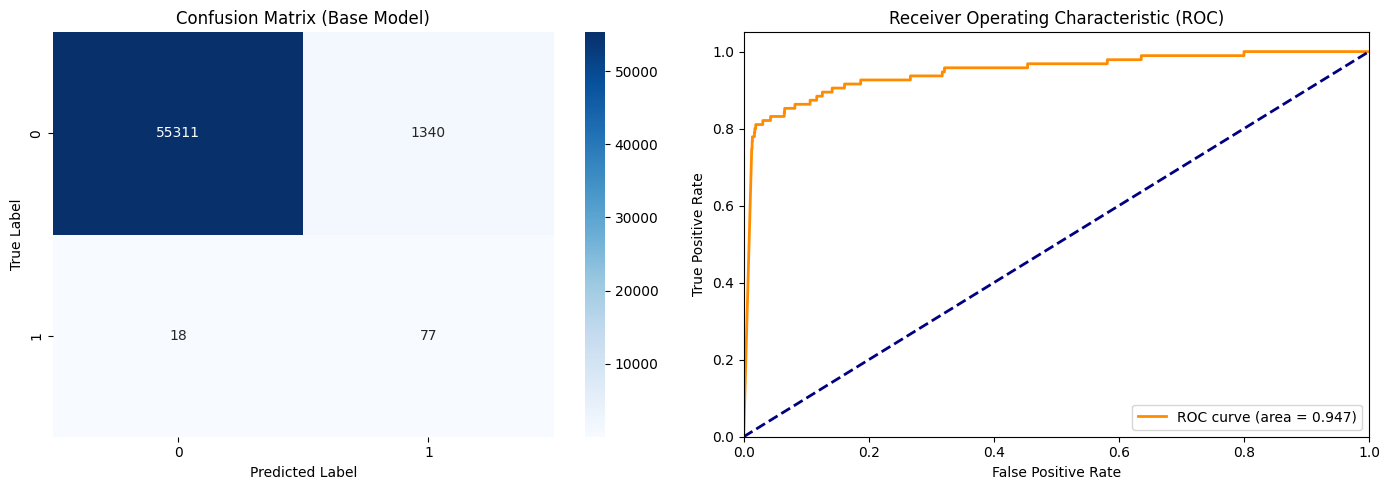

In [210]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_fraud_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix (Base Model)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_fraud_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

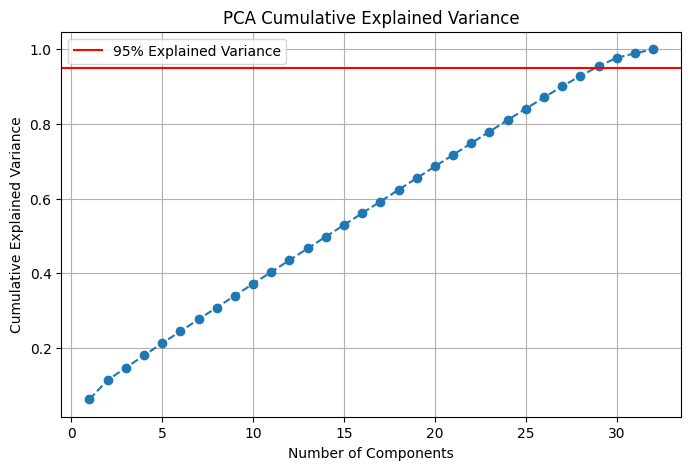

In [211]:
pca = PCA()
pca.fit(X_fraud_train)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

In [212]:
pca = PCA(n_components=28)

X_fraud_train_pca = pca.fit_transform(X_fraud_train)
X_fraud_test_pca = pca.transform(X_fraud_test)

print(f"Original features: {X_fraud_train.shape[1]}")
print(f"Reduced features (PCA): {X_fraud_train_pca.shape[1]}")

nb_pca = GaussianNB()
nb_pca.fit(X_fraud_train_pca, y_fraud_train)

y_pred_pca = nb_pca.predict(X_fraud_test_pca)
y_prob_pca = nb_pca.predict_proba(X_fraud_test_pca)[:, 1]


Original features: 32
Reduced features (PCA): 28


In [213]:
print("=== PCA MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_fraud_test, y_pred_pca):.4f}\n")
print("Classification Report:")
print(classification_report(y_fraud_test, y_pred_pca, zero_division=0))

=== PCA MODEL EVALUATION ===
Accuracy: 0.9764

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.05      0.81      0.10        95

    accuracy                           0.98     56746
   macro avg       0.53      0.89      0.55     56746
weighted avg       1.00      0.98      0.99     56746



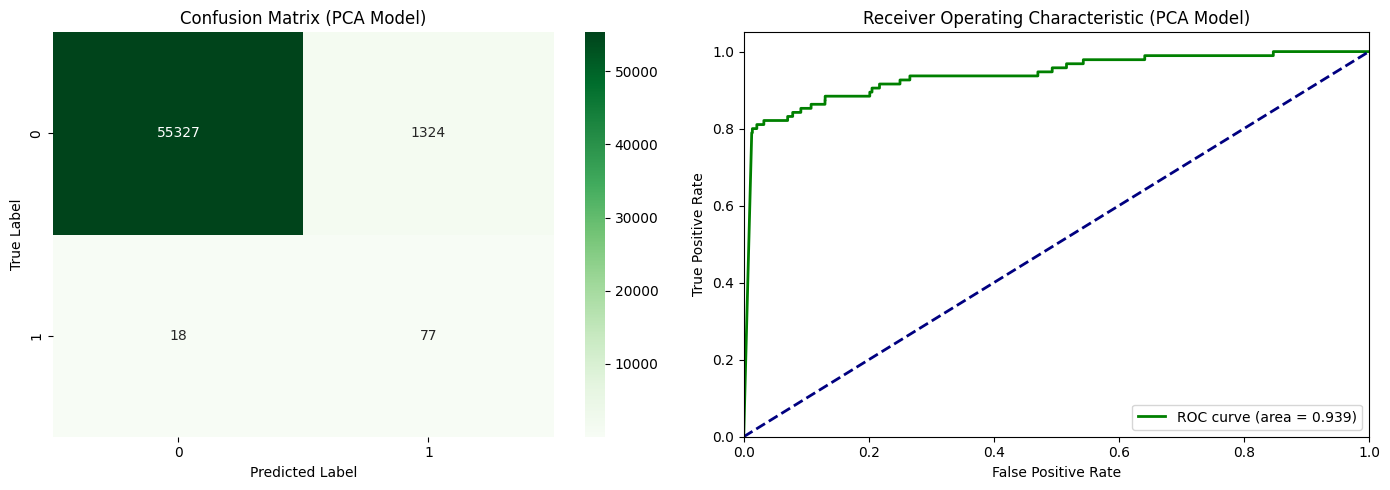

In [214]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm_pca = confusion_matrix(y_fraud_test, y_pred_pca)
sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Greens', ax=axes[0])
axes[0].set_title('Confusion Matrix (PCA Model)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr_pca, tpr_pca, thresholds_pca = roc_curve(y_fraud_test, y_prob_pca)
roc_auc_pca = auc(fpr_pca, tpr_pca)

axes[1].plot(fpr_pca, tpr_pca, color='green', lw=2, label=f'ROC curve (area = {roc_auc_pca:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (PCA Model)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## KNN Regressor

Applied to **Crypto Market Return Prediction**.

- **Why KNN**: Non-parametric, captures local patterns without assumptions about return distribution.
- **Target**: Next-day log-return per coin — stationary, scale-free, and leak-free.
- **Key Fixes Applied**:
  - Trained on **scaled features** — raw prices would dominate euclidean distance.
  - `Close_Lag` features removed — only `Return_Lag` features used.
  - All features computed per coin via `groupby` to prevent cross-coin contamination.
- **Two Variants Evaluated**:
  1. **KNN on scaled features** — `n_neighbors=10`, distance weighting.
  2. **KNN + PCA** — PCA applied on scaled data first (95% variance), then `n_neighbors=40`.
- **Note**: R² near 0 is expected for daily crypto returns — they are largely random noise.

In [215]:
knn = KNeighborsRegressor(n_neighbors=10, p=2, weights="distance")
knn.fit(X_crypto_train_scaled, y_crypto_train)
y_crypto_test_pred = knn.predict(X_crypto_test_scaled)


In [216]:
test_r2  = r2_score(y_crypto_test, y_crypto_test_pred)
test_mae = mean_absolute_error(y_crypto_test, y_crypto_test_pred)
test_mse = mean_squared_error(y_crypto_test, y_crypto_test_pred)

print("=== KNN on scaled features (no PCA) ===")
print(f"R2 Score: {test_r2:.4f}")
print(f"MAE:      {test_mae:.6f}")
print(f"MSE:      {test_mse:.6f}")


=== KNN on scaled features (no PCA) ===
R2 Score: -0.0572
MAE:      0.076100
MSE:      0.012193


In [217]:
pca_crypto = PCA(n_components=0.95)
X_crypto_train_pca = pca_crypto.fit_transform(X_crypto_train_scaled)
X_crypto_test_pca  = pca_crypto.transform(X_crypto_test_scaled)

print(f"PCA: {X_crypto_train_scaled.shape[1]} features → {X_crypto_train_pca.shape[1]} components (95% variance)")


PCA: 20 features → 13 components (95% variance)


In [218]:
knn_pca = KNeighborsRegressor(n_neighbors=40, p=1)
knn_pca.fit(X_crypto_train_pca, y_crypto_train)
y_crypto_test_pred_pca = knn_pca.predict(X_crypto_test_pca)


In [219]:
test_r2_pca  = r2_score(y_crypto_test, y_crypto_test_pred_pca)
test_mae_pca = mean_absolute_error(y_crypto_test, y_crypto_test_pred_pca)
test_mse_pca = mean_squared_error(y_crypto_test, y_crypto_test_pred_pca)

print("=== KNN + PCA on scaled features ===")
print(f"R2 Score: {test_r2_pca:.4f}")
print(f"MAE:      {test_mae_pca:.6f}")
print(f"MSE:      {test_mse_pca:.6f}")


=== KNN + PCA on scaled features ===
R2 Score: 0.0188
MAE:      0.072842
MSE:      0.011316


## Ensemble Regressors

Applied to **Yahoo Finance Stock Return Prediction**.

- **Why Ensemble Methods**: Random Forest and XGBoost handle non-linear feature interactions and are robust to noisy financial data.
- **Target**: Next-day percentage return — `Close.pct_change().shift(-1)`.
- **Hyperparameter Tuning**: Optuna used for both models with time-series cross-validation to avoid look-ahead bias.
- **Models**:
  - **Random Forest**: Best params from Optuna Trial 58 — `n_estimators=210`, `max_depth=5`.
  - **XGBoost**: Best params from Optuna Trial 11 — `n_estimators=380`, `learning_rate=0.279`, GPU-accelerated.
- **Evaluation**: Out-of-sample R², MAE, MSE + visual comparison of predicted vs actual returns.

In [220]:
print("Preparing stock data for modeling...")

sample_ticker = yahoo_data['Ticker'].iloc[0] 
print(f"Selected Ticker: {sample_ticker}")
stock_df = yahoo_data[yahoo_data['Ticker'] == sample_ticker].copy()

stock_df = stock_df.sort_values('Date')

# --- Feature Engineering ---
stock_df['MA_5'] = stock_df['Close'].rolling(window=5).mean()
stock_df['MA_10'] = stock_df['Close'].rolling(window=10).mean()
stock_df['Daily_Return'] = stock_df['Close'].pct_change()

delta = stock_df['Close'].diff()
gain = (delta.where(delta > 0, 0)).fillna(0)
loss = (-delta.where(delta < 0, 0)).fillna(0)
avg_gain = gain.ewm(com=14 - 1, min_periods=14).mean()
avg_loss = loss.ewm(com=14 - 1, min_periods=14).mean()
rs = avg_gain / avg_loss
stock_df['RSI_14'] = 100 - (100 / (1 + rs))

ema_12 = stock_df['Close'].ewm(span=12, adjust=False).mean()
ema_26 = stock_df['Close'].ewm(span=26, adjust=False).mean()
stock_df['MACD_Line'] = ema_12 - ema_26
stock_df['MACD_Signal'] = stock_df['MACD_Line'].ewm(span=9, adjust=False).mean()

stock_df['Return_Lag1'] = stock_df['Daily_Return'].shift(1)
stock_df['Return_Lag2'] = stock_df['Daily_Return'].shift(2)

stock_df['Volatility_10'] = stock_df['Daily_Return'].rolling(window=10).std()

stock_df['Target_Next_Return'] = stock_df['Close'].pct_change().shift(-1)

stock_df = stock_df.dropna()


features = [
    'Close', 'Volume', 
    'MA_5', 'MA_10', 'Daily_Return', 
    'RSI_14', 'MACD_Line', 'MACD_Signal',
    'Return_Lag1', 'Return_Lag2', 'Volatility_10'
]
X_stock = stock_df[features]
y_stock = stock_df['Target_Next_Return']

X_stock_train, X_stock_test, y_stock_train, y_stock_test = train_test_split(
    X_stock, y_stock, 
    test_size=0.2, 
    shuffle=False 
)

print(f"Training shapes: X={X_stock_train.shape}, y={y_stock_train.shape}")
print(f"Testing shapes: X={X_stock_test.shape}, y={y_stock_test.shape}")

Preparing stock data for modeling...
Selected Ticker: A
Training shapes: X=(3133, 11), y=(3133,)
Testing shapes: X=(784, 11), y=(784,)


In [221]:
print("Initializing Final Models with Explicit Best Parameters...")

# 1. Setup Final Random Forest (From Optuna Trial 58)
best_params_rf = {
    'n_estimators': 210, 
    'max_depth': 5, 
    'min_samples_split': 2, 
    'min_samples_leaf': 10,
    'random_state': 42,
    'n_jobs': -1
}
final_rf = RandomForestRegressor(**best_params_rf)

print("Training Final Random Forest...")
final_rf.fit(X_stock_train, y_stock_train)
rf_predictions = final_rf.predict(X_stock_test)


Initializing Final Models with Explicit Best Parameters...
Training Final Random Forest...


In [222]:
# 2. Setup Final XGBoost (From Optuna Trial 11)
best_params_xgb = {
    'n_estimators': 380, 
    'learning_rate': 0.27926006434202694, 
    'max_depth': 6, 
    'subsample': 0.5218003352159574, 
    'colsample_bytree': 0.7341882687722235, 
    'min_child_weight': 1, 
    'gamma': 1.0703765890972565, 
    'reg_alpha': 0.016006678280215965, 
    'reg_lambda': 8.214406800943035,
    'objective': 'reg:squarederror',
    'random_state': 42,
    'tree_method': 'hist',
    'device': 'cuda'
}
final_xgb = XGBRegressor(**best_params_xgb)

print("Training Final XGBoost...")
final_xgb.fit(X_stock_train, y_stock_train)
xgb_predictions = final_xgb.predict(X_stock_test)

Training Final XGBoost...


In [223]:
# 3. Print Evaluation Metrics
print("\n--- Final Model Evaluation (Out-of-Sample) ---")
print("RANDOM FOREST:")
print(f"  MSE: {mean_squared_error(y_stock_test, rf_predictions):.6f}")
print(f"  MAE: {mean_absolute_error(y_stock_test, rf_predictions):.6f}")
print(f"  R2:  {r2_score(y_stock_test, rf_predictions):.4f}")

print("\nXGBOOST:")
print(f"  MSE: {mean_squared_error(y_stock_test, xgb_predictions):.6f}")
print(f"  MAE: {mean_absolute_error(y_stock_test, xgb_predictions):.6f}")
print(f"  R2:  {r2_score(y_stock_test, xgb_predictions):.4f}")


--- Final Model Evaluation (Out-of-Sample) ---
RANDOM FOREST:
  MSE: 0.000234
  MAE: 0.010517
  R2:  -0.0399

XGBOOST:
  MSE: 0.000225
  MAE: 0.010355
  R2:  -0.0011


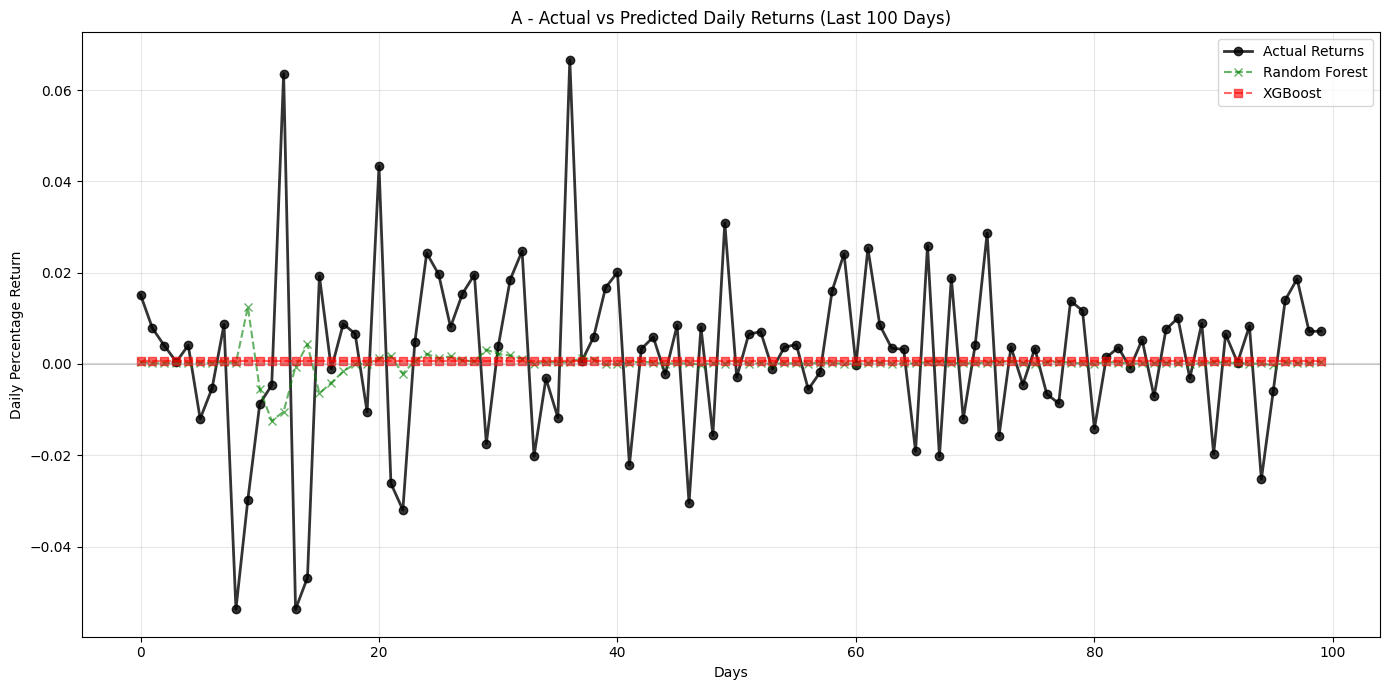

In [224]:
# 4. Plotting Actuals vs Both Models
plt.figure(figsize=(14, 7))
days_to_plot = 100 

plt.plot(y_stock_test.values[-days_to_plot:], label='Actual Returns', color='black', marker='o', alpha=0.8, linewidth=2)
plt.plot(rf_predictions[-days_to_plot:], label='Random Forest', color='green', marker='x', alpha=0.6, linestyle='--')
plt.plot(xgb_predictions[-days_to_plot:], label='XGBoost', color='red', marker='s', alpha=0.6, linestyle='--')

try:
    ticker_name = sample_ticker
except NameError:
    ticker_name = "Stock"

plt.title(f"{ticker_name} - Actual vs Predicted Daily Returns (Last 100 Days)")
plt.xlabel("Days")
plt.ylabel("Daily Percentage Return")
plt.axhline(0, color='gray', linestyle='-', alpha=0.3)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Autoencoder for Anomaly Detection

## Splitting and Isolation Normal and Fraud Data

In [242]:
X_fraud_train, X_fraud_test, y_fraud_train, y_fraud_test = train_test_split(
    X_fraud, y_fraud,
    test_size=0.2,
    random_state=42,
    stratify=y_fraud
)

# Isolate NORMAL data for training
X_train_normal = X_fraud_train[y_fraud_train == 0]
X_train_fraud = X_fraud_train[y_fraud_train == 1]
y_train_fraud = y_fraud_train[y_fraud_train == 1]

# Add the rescued fraud data to the test set
X_fraud_test = pd.concat([X_fraud_test, X_train_fraud], axis=0)
y_fraud_test = pd.concat([y_fraud_test, y_train_fraud], axis=0)

## AutoEncoder Structure and Training

In [243]:
input_dim = X_train_normal.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder
encoder = Dense(16, activation="relu")(input_layer)
encoder = Dense(8, activation="relu")(encoder)

# Decoder
decoder = Dense(8, activation='relu')(encoder)
decoder = Dense(16, activation='relu')(decoder)

decoder = Dense(input_dim, activation='linear')(decoder)

autoencoder = Model(inputs=input_layer, outputs=decoder)

autoencoder.compile(optimizer='adam', loss='mean_squared_error')

history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=50,
    batch_size=32,
    shuffle=True,
    verbose=1
)

Epoch 1/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - loss: 1.2613
Epoch 2/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.4545
Epoch 3/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.4275
Epoch 4/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.4151
Epoch 5/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.4148
Epoch 6/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.4078
Epoch 7/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.4108
Epoch 8/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.4071
Epoch 9/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.3842
Epoch 10/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.3807
Epoch 11/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.3768
Epoch 12/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.3754
Epoch 13/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.3759
Epoch 14/50
7082/7082 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.3647
Epoch 15/50
708

## Predictions

In [244]:
train_predictions = autoencoder.predict(X_train_normal)
mse_train = np.mean(np.power(X_train_normal - train_predictions, 2), axis=1)


best_threshold = np.percentile(mse_train, 99)

print(f"Statistically Calculated Threshold: {best_threshold}")

7082/7082 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step
Statistically Calculated Threshold: 2.1190930532918717


## Evaluation

In [247]:
# Predict on the unseen test set
test_predictions = autoencoder.predict(X_fraud_test)
mse_test = np.mean(np.power(X_fraud_test - test_predictions, 2), axis=1)

# Classify as Fraud (1) if the error is higher than chosen threshold
y_test_pred = [1 if error > best_threshold else 0 for error in mse_test]

print(classification_report(y_fraud_test, y_test_pred))

1786/1786 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56651
           1       0.38      0.79      0.52       473

    accuracy                           0.99     57124
   macro avg       0.69      0.89      0.76     57124
weighted avg       0.99      0.99      0.99     57124



## Reconstruction Visualization

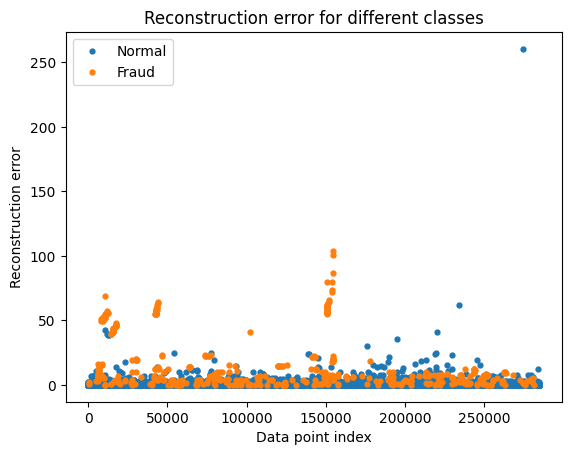

In [254]:
error_df = pd.DataFrame({'reconstruction_error': mse_test, 'true_class': y_fraud_test})

groups = error_df.groupby('true_class')
fig, ax = plt.subplots()

for name, group in groups:
    ax.plot(group.index, group.reconstruction_error, marker='o', ms=3.5, linestyle='',
            label= "Fraud" if name == 1 else "Normal")
ax.legend()
plt.title("Reconstruction error for different classes")
plt.ylabel("Reconstruction error")
plt.xlabel("Data point index")
plt.show()